# Week 3 · Part B — Lie Factor, computed in Python

Tufte's Lie Factor = (effect shown in the graphic) / (effect in the data), with effect = (final − initial) / initial. Honest = 1.0 (accepted 0.95–1.05).
Data: `data/case07_lie_factor.csv` (five measured graphics) and `data/case07_dual_axis_series.csv` (Chart F). All data is **synthetic**, generated for CDB601220.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
from vizlib import lie_factor, lie_verdict, PALETTE, style_defaults

style_defaults(dpi=100)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 80)
FIG = Path("figs"); FIG.mkdir(exist_ok=True)
lf = pd.read_csv("data/case07_lie_factor.csv")
lf[["chart_id", "subject", "value_start", "value_end", "ink_start", "ink_end", "ink_unit", "ink_dimension"]]

,chart_id,subject,value_start,value_end,ink_start,ink_end,ink_unit,ink_dimension
0,A,Corporate tax rate,30.0,32.0,4.0,24.0,mm,1
1,B,Federal health budget (Rs bn),40.0,60.0,1.0,1.5,x scale,2
2,C,Export earnings ($ bn),25.0,30.0,5.0,6.0,cm,1
3,D,Air-pollution index,100.0,150.0,8.0,9.0,cm,1
4,E,City population (millions),2.0,8.0,1.0,4.0,x radius,2


## 1 · The audit table (5 marks)
`vizlib.lie_factor()` is called once per graphic, using the `ink_dimension` that the file records (1 = length, 2 = area).

In [2]:
rows = []
for _, r in lf.iterrows():
    L, de, ge = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, int(r.ink_dimension))
    rows.append({"chart": r.chart_id, "subject": r.subject, "ink_dim": int(r.ink_dimension),
                 "data effect": f"{de:+.1%}", "graphic effect": f"{ge:+.1%}", "Lie Factor": round(L, 2), "verdict": lie_verdict(L)})
audit = pd.DataFrame(rows).set_index("chart")
print(audit.to_string())

                             subject  ink_dim data effect graphic effect  Lie Factor             verdict
chart                                                                                                   
A                 Corporate tax rate        1       +6.7%        +500.0%       75.00  exaggerates 75.00x
B      Federal health budget (Rs bn)        2      +50.0%        +125.0%        2.50   exaggerates 2.50x
C             Export earnings ($ bn)        1      +20.0%         +20.0%        1.00              honest
D                Air-pollution index        1      +50.0%         +12.5%        0.25  understates (0.25)
E         City population (millions)        2     +300.0%       +1500.0%        5.00   exaggerates 5.00x


## 2 · Exactly one is honest — and what the other four do wrong (3 marks)

**Honest: Chart C** (exports, bars from zero, 5.0 → 6.0 cm for 25 → 30): data effect +20.0 %, graphic effect +20.0 %, **LF = 1.00**. Length encodes the value and the baseline is zero, so ratios of ink = ratios of data.

| Chart | What the ink is doing wrong | LF |
|---|---|---|
| **A** corporate tax | Bars start at 29.6 %, so only the *tips* are drawn: 30 → 32 is a **+6.7 %** change in the data but the ink goes 4 → 24 mm (**+500 %**). The ink no longer represents the whole quantity. | **75** |
| **B** health budget | A coin icon is scaled 1.5× in **both** height and width. The *length* grows 1.5× but the **area** (what the eye reads) grows 1.5² = 2.25×: +125 % ink for a +50 % data change. | **2.5** |
| **D** air-pollution index | Bars 8.0 → 9.0 cm for a 100 → 150 rise: +12.5 % ink for a **+50 %** data change. The ink per unit *shrinks* (0.080 → 0.060 cm per index point), which is what you get when bars carry a large block of "dead" ink that does not depend on the value (an axis starting far below zero) — so the rise is squashed. | **0.25** |
| **E** city population | A bubble whose **radius** ∝ value (1 → 4, i.e. ×4) when the data grew ×4 ( 2 → 8 ) — fine for the radius, but the reader sees **area** = 16× (+1,500 %) for a +300 % change. | **5.0** |

## 3 · Which need `ink_dimension = 2`, and what goes wrong if you leave it at 1 (3 marks)

In [3]:
wrong = []
for _, r in lf[lf.ink_dimension == 2].iterrows():
    L2, _, _ = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, 2)
    L1, _, _ = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, 1)
    wrong.append({"chart": r.chart_id, "LF with ink_dimension=2 (correct)": round(L2, 2), "LF left at 1 (wrong)": round(L1, 2)})
pd.DataFrame(wrong).set_index("chart")

,LF with ink_dimension=2 (correct),LF left at 1 (wrong)
chart,,
B,2.5,1.0
E,5.0,1.0


**Charts B and E** (the coin icon and the bubble) encode the value in an **area**. Leave `ink_dimension` at 1 and the function measures the *length* ratio instead of the *area* ratio,
so it reports **B as LF = 1.0 instead of 2.5** (the icon is 1.5× longer, and the data rose 1.5×) and **E as LF = 1.0 instead of 5.0** (the radius is 4× larger and the data rose 4×) — both distorted graphics would be certified honest,
because the eye reads **area** (the square of the scale), not the length you measured with the ruler. (Table above: 2.5 → 1.0 and 5.0 → 1.0.)

## 4 · One has LF below 1 — why an understated chart is still a distortion (2 marks)
**Chart D (LF = 0.25).** The data rose 50 % but the graphic shows 12.5 %. Honesty is symmetric: the reader's picture of the world should match the data in *both* directions; an understated chart leads the reader to a wrong decision just as surely as an inflated one.
**Who benefits:** whoever would rather the public did not worry — here, a government or industry that is responsible for air quality (a 50 % deterioration made to look like a small blip). An exaggerated chart (A, B, E) typically benefits the party selling a rise or a growth story; an understated one benefits the party that wants a rise to look small.

## 5 · Chart F — the dual-axis chart from Part A, case 7 (2 marks)

In [4]:
d7 = pd.read_csv("data/case07_dual_axis_series.csv")
print(d7.assign(profit=d7.revenue_pkr_m - d7.cost_pkr_m, margin_pct=((d7.revenue_pkr_m - d7.cost_pkr_m) / d7.revenue_pkr_m * 100).round(1)))
try:
    # what would we even pass as "ink"? On a dual-axis chart the same vertical distance means 30 units on the left and 16 on the right.
    left_units_per_cm = (80 - 50) / 5.0; right_units_per_cm = (56 - 40) / 5.0
    print(f"\nOne cm of height = {left_units_per_cm:.1f} PKR m on the revenue axis but {right_units_per_cm:.1f} PKR m on the cost axis (for a 5 cm tall plot).")
    print("Lie Factor of 'revenue + cost'? There is no single ink-per-unit to compare, so no single LF exists.")
    # we CAN compute one per series, but each only tells us about its own axis
    for name, col, lo, hi in [("revenue", "revenue_pkr_m", 50, 80), ("cost", "cost_pkr_m", 40, 56)]:
        v0, v1 = d7[col].iloc[0], d7[col].iloc[-1]
        i0, i1 = (v0 - lo) / (hi - lo), (v1 - lo) / (hi - lo)          # ink height above the axis floor (0..1)
        L, de, ge = lie_factor(v0, v1, i0, i1, 1)
        print(f"  {name:8s} Jan->Jun data {de:+.0%}, ink {ge:+.0%}  -> per-series LF {L:.2f} (truncated axis from {lo})")
except Exception as e:
    print("error:", e)

  month  revenue_pkr_m  cost_pkr_m  profit  margin_pct
0   Jan             52          44       8        15.4
1   Feb             58          46      12        20.7
2   Mar             61          47      14        23.0
3   Apr             66          49      17        25.8
4   May             71          51      20        28.2
5   Jun             78          53      25        32.1

One cm of height = 6.0 PKR m on the revenue axis but 3.2 PKR m on the cost axis (for a 5 cm tall plot).
Lie Factor of 'revenue + cost'? There is no single ink-per-unit to compare, so no single LF exists.
  revenue  Jan->Jun data +50%, ink +1300%  -> per-series LF 26.00 (truncated axis from 50)
  cost     Jan->Jun data +20%, ink +225%  -> per-series LF 11.00 (truncated axis from 40)


**I cannot compute a single Lie Factor for Chart F, and the reason is the lesson.** The formula assumes **one** mapping from data to ink: the same 1 cm of height must mean the same number of data units everywhere in the graphic.
A dual-axis chart deliberately breaks that assumption — the same centimetre means 6 PKR m on the left axis and 3.2 PKR m on the right (for a 5 cm plot) — so "graphic effect ÷ data effect" has no single value: it depends on which axis you read.
The only thing one can compute is a Lie Factor *per series* against its own truncated axis (revenue ≈ **26**, cost ≈ **11**, printed above — large because each axis is cut off at 50 and 40), and even those say nothing about the *relationship between* the two lines, which is what the chart is used to claim.

**What the data actually shows** (printed above): revenue (52 → 78) is above cost (44 → 53) **in every month**; profit grows 8 → 25 PKR m and the margin goes from 15% to 32%. The "cost above revenue until May" is produced entirely by choosing two different axis ranges (50–80 and 40–56).
The honest chart puts both series on **one** axis (from zero), or shows profit as its own panel — see Part A, case 7.

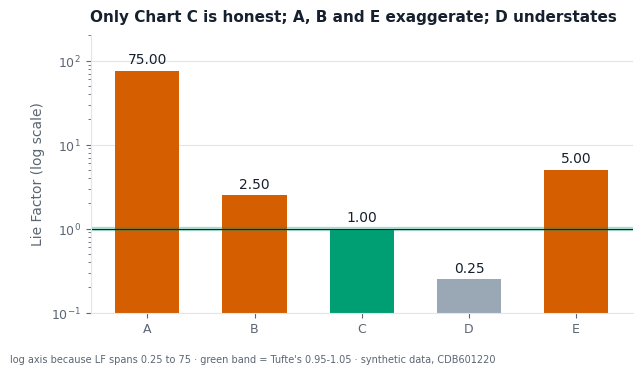

In [5]:
# a one-glance chart of Part B: the Lie Factors, with the honest band marked
fig, ax = plt.subplots(figsize=(7, 3.6))
labs = list(audit.index); vals = audit["Lie Factor"].astype(float).values
cols = [PALETTE["series"][2] if 0.95 <= v <= 1.05 else (PALETTE["muted"] if v < 0.95 else PALETTE["series"][1]) for v in vals]
bars = ax.bar(labs, vals, color=cols, width=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axhspan(0.95, 1.05, color=PALETTE["series"][2], alpha=0.25); ax.axhline(1, color=PALETTE["ink"], lw=0.8)
ax.set_yscale("log"); ax.set_ylim(0.1, 200); ax.grid(axis="x", visible=False)
ax.set_ylabel("Lie Factor (log scale)")
ax.set_title("Only Chart C is honest; A, B and E exaggerate; D understates", loc="left", fontsize=11)
fig.text(0.01, -0.03, "log axis because LF spans 0.25 to 75 · green band = Tufte's 0.95-1.05 · synthetic data, CDB601220", fontsize=7, color=PALETTE["ink_soft"])
fig.savefig(FIG / "B_lie_factors.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()